# Notebook 04 — Imitation training: teaching smolVLA to drive and to read

In notebook 03 we turned the 296 scripted drives into training samples: a camera picture, the car's speed and an
instruction, together with the next 10 actions the driver took. Now a **vision-language-action model** learns to
predict those actions. This is *imitation learning*: the model copies the demonstrations.

We train the same recipe **twice**, with two different *action heads* (the part that produces the driving commands):

| Run | Action head | Starts from |
|---|---|---|
| A | **smolVLA's own head** | smolVLA's pretraining on about 23,000 robot-*arm* demonstrations |
| B | **a car head**: the same design, built for the car's 3 commands | random numbers: it learns only from our drives |

Comparing them answers a real question: does a head pretrained on robot arms help a car?

**What you will learn here**
1. How a VLA is put together: a *reader* (vision-language model) and an *action head* (flow matching).
2. Why the reader must be fed its inputs exactly the way it was trained, and what goes wrong otherwise.
3. An *auxiliary task* (a quiz) that makes the model link the words to what it sees.
4. How to read training graphs, and how to test a driving model properly: fixed test drives, 95% ranges, and
   drive-by-drive comparisons.

**Time:** about 35 minutes of training per head and 10 minutes of tests per head, so about **1.5–2 hours** on an
RTX 4080-class GPU (much longer on a Mac). Each training cell can run while you read on.

## 1. Setup

**Close other notebooks that use the GPU first** (*Kernel → Shut Down Kernel*): training needs about 9 GB of GPU
memory. `PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True` is set **before** importing torch; without it GPU memory
gets fragmented and long runs can crash with "out of memory" although enough is free.

In [1]:
import os, sys, json, time, gc, subprocess
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")  # must happen before torch is imported
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
RUNS = PROJECT_ROOT / "runs"
PREP = RUNS / "datasets" / "scripted_close_prep.json"                 # written by notebook 03
CHECKPOINTS = {"smolvla": RUNS / "checkpoints" / "bc_smolvla_head.pt",   # what this notebook produces;
               "car":     RUNS / "checkpoints" / "bc_car_head.pt"}       # notebook 05 starts from one of them
TAGS = {head: "nb04_" + ck.stem for head, ck in CHECKPOINTS.items()}     # names of the test results
NAMES = {"smolvla": "smolVLA head", "car": "car head"}

import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
from carsim.device import pick_device, describe, empty_cache
DEVICE = pick_device()
print(describe())
assert PREP.exists(), "Run notebook 03 first: it writes the training file."

device = cuda: NVIDIA GeForce RTX 4080 SUPER, 15.6 GB | PyTorch 2.15.0+cu134 | Linux 7.2.14-arch1-1


## 2. The model: a reader and an action head

```
 camera picture ─► vision encoder (SigLIP) ─► 64 picture pieces ─┐
                                                                 ├─► READER: language model, 16 layers ─┐
 "drive to the red ball" ─► word pieces ─────────────────────────┘   (mixes picture and words)        │
 car speed ─► 1 piece ──────────────────────────────────────────────────────────────────────────────────┤
                                                                                                        ▼
                         random noise ─► ACTION HEAD: 10 refining steps ─► the next 10 actions (vx, vy, wz)
                                         (looks at the reader's notes at every layer)
```

* **The reader** is **SmolVLM2**, a small vision-language model (the kind of model that can answer questions about
  pictures). smolVLA keeps only the first 16 of its 32 language layers: enough to understand the scene, and half the
  cost. Its job is to write "notes" about the scene in which the words and the picture are already connected:
  *the red ball the instruction talks about is over there, on the left*.
* **The action head** (smolVLA calls it the *action expert*) is a second, smaller transformer (about 100 million
  numbers) that turns the notes into actions. It works by **flow matching**: it starts from random noise and refines it
  in 10 small steps into a chunk of 10 actions, like a sculptor. This lets it represent "left OR right around the
  obstacle" without averaging the two into "straight into it" (notebook 02, multimodality).
* **Which parts learn.** The vision encoder and the first 12 reader layers stay **locked**: they already know a lot
  from millions of pictures, and changing them would cost memory and risk forgetting. The **last 4 reader layers**
  learn with a 10× smaller learning rate (a nudge, not a rewrite). The **action head** learns at the normal rate.

## 3. Feeding the reader the way it was trained

A neural network only works well on inputs that look like the ones it was trained on. SmolVLM2 was trained with its
own input format. smolVLA's published code feeds it differently in three ways, inherited from the model smolVLA's
design came from (π0, which uses a different language model, Gemma). We use **SmolVLM2's own format**:

| Setting | smolVLA as published | SmolVLM2's own format (what we use) |
|---|---|---|
| Size of the input pieces | every picture and word piece **multiplied by √960 ≈ 31** | unchanged (SmolVLM2 never scales its inputs; Gemma does, internally) |
| Attention | **two-way**: every piece sees every other piece | **one-way**: each piece sees only the pieces before it |
| Image markers | none | special tokens mark where the picture starts and ends |

**Why the ×31 matters.** Each reader layer works like this: take the current notes, *resize a copy to a standard size*,
work out a correction from it, and **add the correction back**. The correction has a normal size whatever the notes'
size. If the notes are 31 times too big, every correction is a small dent in them, so 16 layers barely change the
picture pieces and the words never really get mixed into them. We measured this: the 16 layers change the picture
pieces by about 190% in SmolVLM2's own format, but only by about 13% with ×31.

**What it changes in practice.** We tested whether the reader's notes say *which of two objects the words mean*
(a small add-on was trained to answer from the notes alone, on pictures with two objects and both possible
instructions). As smolVLA feeds it: right 50% of the time, a coin flip. In SmolVLM2's own format: 93%. All three
settings are needed; with any one missing it stays near 50%. Models trained with SmolVLM2's format also drove
clearly better on every test below.

`carsim.vla.apply_reader_fix(policy)` applies the three settings, and every checkpoint records the format it was
trained with (a small `_meta.json` file next to it), so loading always uses the right one. The cell below shows the
sizes of the input pieces, both ways. (It loads smolVLA, about 0.9 GB, once; the first time it is downloaded.)

In [2]:
from carsim.vla import load_smolvla, apply_reader_fix, prepare_inputs, format_prompts
img = torch.rand(1, 3, 256, 256)            # any picture will do for measuring sizes
for name in ("smolVLA as published", "SmolVLM2's own format"):
    pol = load_smolvla(DEVICE)
    if name != "smolVLA as published":
        apply_reader_fix(pol)
    inp = prepare_inputs(pol, img, format_prompts(pol, ["drive to the red ball"]), torch.zeros(1, 3), device=DEVICE)
    with torch.no_grad():
        emb, pad, att = pol.model.embed_prefix(*inp)
    size = emb[0].float().norm(dim=-1).cpu()
    n_mark = pol.model.global_image_start_token.numel() if pol.model.add_image_special_tokens else 0  # marker pieces before the picture
    words = size[n_mark + 64 + (1 if n_mark else 0):-1]                                               # after the end marker, before the speed
    print(f"{name:24s} picture pieces: size {size[n_mark:n_mark + 64].mean():7.1f} | word pieces: size {words.mean():5.1f}"
          f" | one-way attention: {bool(att[0, :-1].all())}")
    del pol; gc.collect(); empty_cache(DEVICE)

/home/mayur/Projects/obstacle_avoidance/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 6243.04it/s]

Reducing the number of VLM layers to 16 ...


... (2 outputs left out)

Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 6432.34it/s]

Reducing the number of VLM layers to 16 ...


SmolVLM2's own format    picture pieces: size   132.1 | word pieces: size   3.4 | one-way attention: True


**How to read it.** In SmolVLM2's own format the picture pieces are about 130 and the word pieces about 3 in size:
these are the sizes SmolVLM2 learned with. smolVLA's ×31 makes them about 4,000 and 100. (The exact numbers depend
on the picture and the words; the ratio of 31 is what matters.)

## 4. The quiz: making the model connect words and objects

Imitation alone only says "do what the driver did". In many scenes the model can get that right without reading the
instruction, for example by driving to the most obvious object. So during training we add a **quiz** (an
*auxiliary task*). For every training picture a small extra head (0.2 million numbers) answers:

> *"Where is the green cube?"*  →  **not visible** / **left** / **centre** (within 10°) / **right**

* The object asked about is chosen **at random** among the room's objects, mostly ones in view, and the question names
  it by colour and shape. Asking about a *random* object (not just the goal) is what makes the quiz work: the only way
  to answer is to read the name and find *that* object.
* The answer comes from the simulator's records (notebook 02's `sim.*` columns), so it is graded automatically.
* The quiz loss counts **0.1×** as much as the driving loss. It is a side lesson that shapes the reader's notes; the
  quiz head is thrown away after training, and the car never uses it while driving.

Section 6 shows real quiz questions from a training batch, with the correct answers.

## 5. The two action heads

| | smolVLA head | car head |
|---|---|---|
| Design | smolVLA's action expert: 16 layers, alternating "look at each other" and "look at the reader's notes" | **exactly the same design** |
| Start | pretrained with smolVLA on robot-arm data | random numbers (`carsim.vla.make_car_head`) |
| Actions | 32 numbers per step (arms have many joints); we use the first 3 and ignore the rest | exactly 3 numbers per step: vx, vy, wz |
| Speed input | 32 numbers, 3 used | 3 numbers |

Everything else is identical: the data, the reader settings, the quiz, the number of steps and the random seed.

## 6. Run A: train with smolVLA's head

`BCConfig` holds every training setting, with comments (`carsim/bc_train.py`). The defaults are this project's
recipe; only the head changes between the two runs. Creating the trainer loads smolVLA and the training data
(about a minute).

In [2]:
from carsim.bc_train import BCConfig, BCTrainer, plot_training, CLASSES

def make_trainer(head):
    cfg = BCConfig(head=head)
    tr = BCTrainer(cfg, PREP, device=DEVICE)
    print(f"head = {head} | data: {tr.data_note}")
    print("numbers that learn:", {k: f"{v / 1e6:.1f} million" for k, v in tr.n_trainable.items()})
    return cfg, tr

cfg, tr = make_trainer("smolvla")
for k, v in vars(cfg).items():
    print(f"  {k:16s} {v}")

/home/mayur/Projects/obstacle_avoidance/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 6498.84it/s]

Reducing the number of VLM layers to 16 ...


head = smolvla | data: 17210 frames, plain shuffling
numbers that learn: {'driver': '99.9 million', 'reader': '39.3 million', 'quiz': '0.2 million'}
  steps            5000
  batch            32
  seed             0
  lr               0.0001
  warmup           300
  unlock_layers    4
  reader_lr        1e-05
  quiz             random
  quiz_weight      0.1
  quiz_lr          0.001
  quiz_p_visible   0.8
  mirror_p         0.0
  head             smolvla
  fmt_markers      True
  fmt_causal       True
  fmt_unscaled     True
  log_every        100
  val_every        1000


**Reading the printout:**
* **driver ~100 million** numbers (the action head) learn at the normal rate (`lr` = 1e-4).
* **reader ~39 million**: the last 4 of its 16 language layers, at a **10× smaller** learning rate (`reader_lr`).
* **quiz ~0.2 million**: the small quiz head.
* `mirror_p = 0.0`: no mirroring for these drives (notebook 03, section 7). The `fmt_*` settings are SmolVLM2's own
  input format (section 3).

The quiz questions of one batch (the answer is what the quiz head must say):

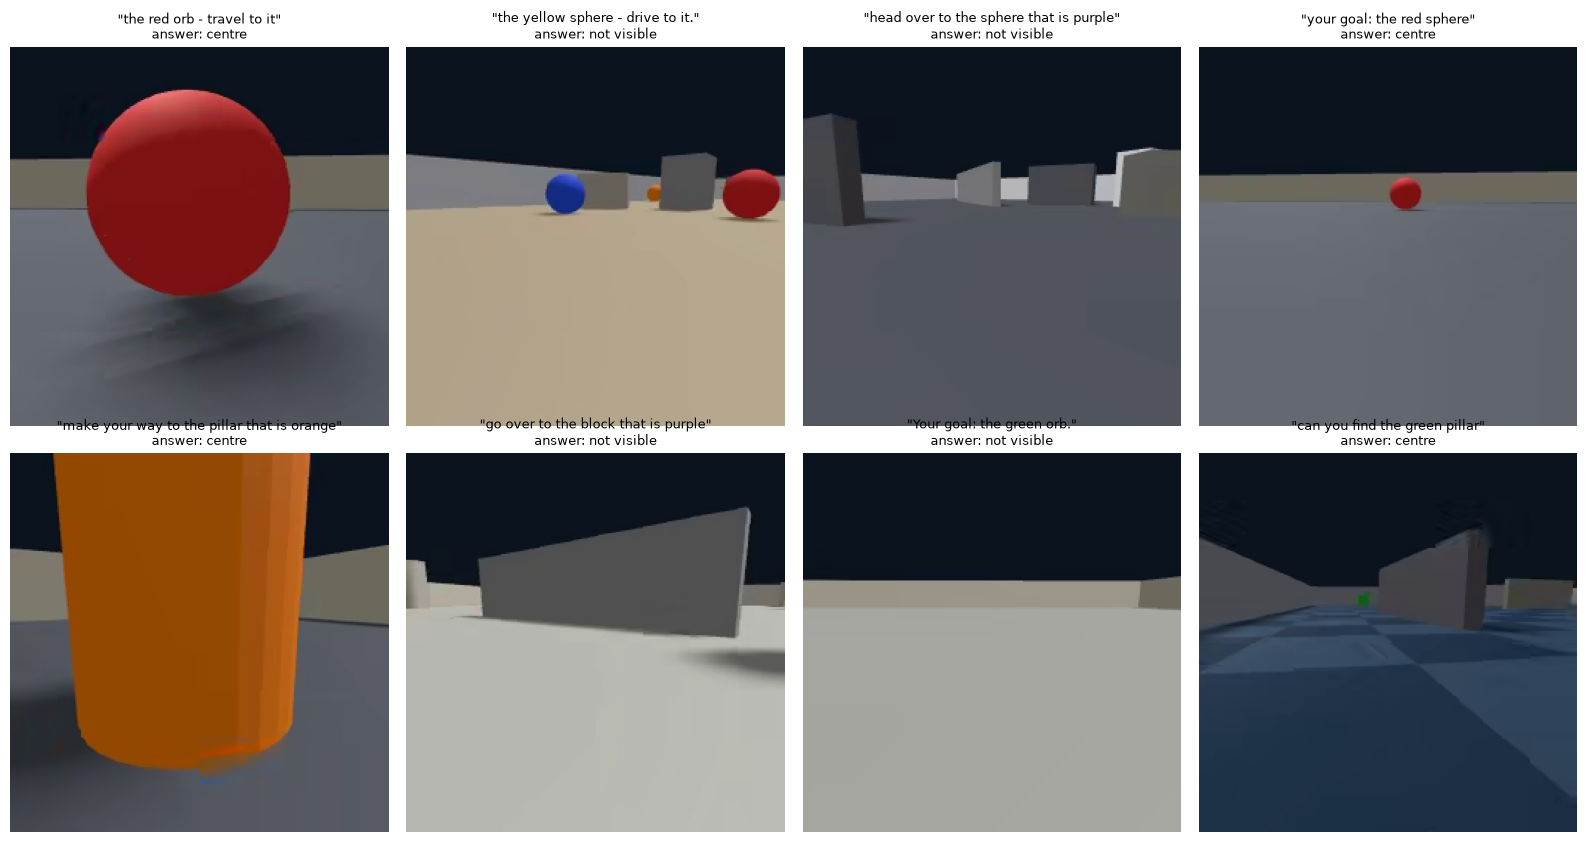

In [3]:
b, prompts, labels = tr.quiz_examples(8)   # 8 training samples; doesn't disturb the training's random numbers
fig, axes = plt.subplots(2, 4, figsize=(16, 8.4))
for ax, img, q, lab in zip(axes.flat, b["image"], prompts, labels):
    ax.imshow(img.permute(1, 2, 0).numpy()); ax.axis("off")
    ax.set_title(f'"{q}"\nanswer: {CLASSES[int(lab)]}', fontsize=9)
plt.tight_layout(); plt.show()

### 6.1 Train

About **35 minutes** for 5,000 steps of 32 samples. The graphs update every 100 steps:

| Graph | What it shows | Healthy |
|---|---|---|
| **Driving loss** (log scale) | how far the predicted actions are from the scripted driver's | falls quickly at first, then slowly; ends near 0.06 |
| **Quiz loss** | how wrong the quiz answers are | falls |
| **Quiz: share answered right** | blue = training pictures, orange dots = validation pictures (never trained on), dotted = random guessing (25%) | both rise well above 25%; validation ends near 90% |

**Warning signs:** a driving loss that rises again for many steps (learning rate too high), or a big, growing gap
between training and validation quiz accuracy (memorising the training pictures). A small gap is normal.

The learning rate warms up over the first 300 steps and then slowly decays, which is why the loss falls fastest early on.
If you stop the cell (■), the trainer keeps its progress; run the cell again to continue.

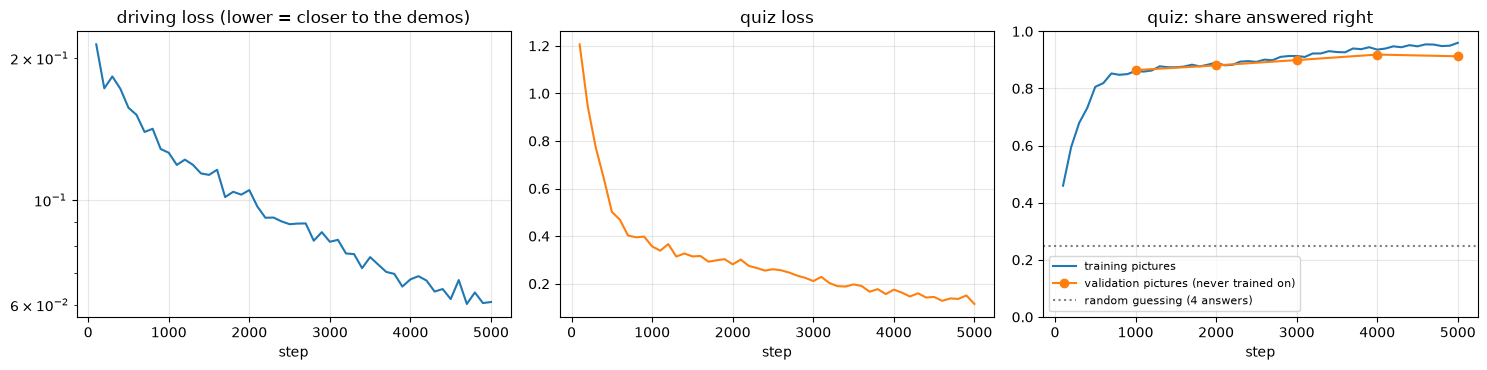

step 5000/5000  driving loss 0.061  quiz right 96%  (validation 91%) | 32.7 min


In [4]:
fig = plt.figure(figsize=(15, 3.8))
try:
    for row in tr.train():
        plot_training(tr.log, fig)
        clear_output(wait=True)
        display(fig)
        msg = f"step {row['step']}/{cfg.steps}  driving loss {row['driving_loss']:.3f}  quiz right {row['quiz_train_acc']:.0%}"
        if row.get("quiz_val_acc") is not None:
            msg += f"  (validation {row['quiz_val_acc']:.0%})"
        print(msg, f"| {row['minutes']:.1f} min")
finally:
    plt.close(fig)

### 6.2 Save

The saved file holds only the numbers that changed (the action head + the 4 unlocked reader layers), about 0.5 GB.
Everything else comes from the downloaded smolVLA. `carsim.vla.load_bc_policy(checkpoint)` puts them together again,
reading the head type and input format from the `_meta.json` file saved next to it. Then we free the GPU memory for
the next run.

In [5]:
if tr.step < cfg.steps:
    print(f"WARNING: training stopped at step {tr.step} of {cfg.steps}; saving anyway")
print("saved", tr.save(CHECKPOINTS[cfg.head]))
del tr; gc.collect(); empty_cache(DEVICE)

saved /home/mayur/Projects/obstacle_avoidance/runs/checkpoints/bc_smolvla_head.pt


## 7. Run B: train with the car head

Exactly the same, with `head="car"`. **Expect** the driving loss to start a little higher than in run A (this head
starts from random numbers, while smolVLA's head already knows how to turn notes into smooth motions) and to end at
about the same level. Another 35 minutes.

In [7]:
cfg, tr = make_trainer("car")

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 7802.48it/s]

Reducing the number of VLM layers to 16 ...


head = car | data: 17210 frames, plain shuffling
numbers that learn: {'driver': '99.8 million', 'reader': '39.3 million', 'quiz': '0.2 million'}


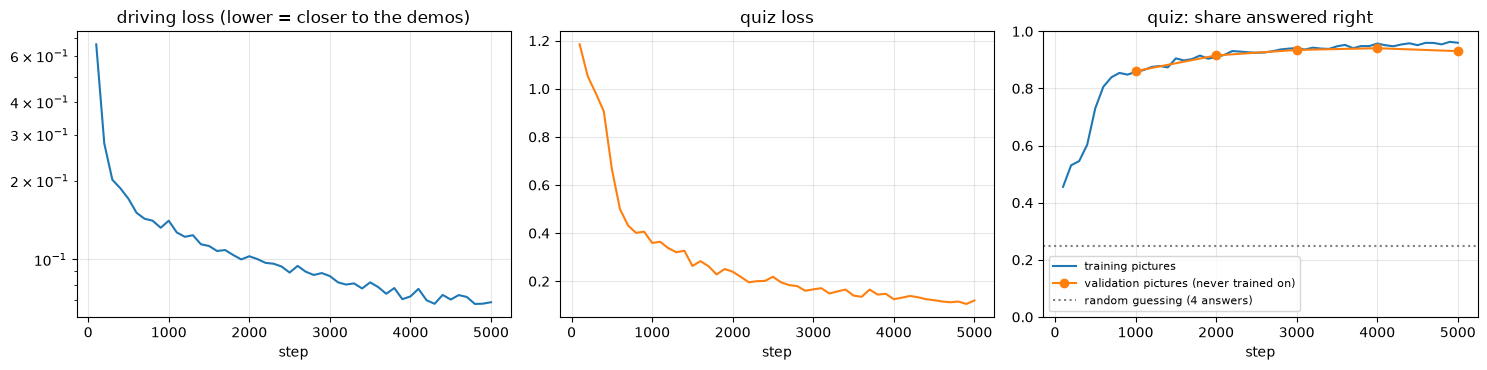

step 5000/5000  driving loss 0.069  quiz right 96%  (validation 93%) | 32.9 min


In [8]:
fig = plt.figure(figsize=(15, 3.8))
try:
    for row in tr.train():
        plot_training(tr.log, fig)
        clear_output(wait=True)
        display(fig)
        msg = f"step {row['step']}/{cfg.steps}  driving loss {row['driving_loss']:.3f}  quiz right {row['quiz_train_acc']:.0%}"
        if row.get("quiz_val_acc") is not None:
            msg += f"  (validation {row['quiz_val_acc']:.0%})"
        print(msg, f"| {row['minutes']:.1f} min")
finally:
    plt.close(fig)

In [9]:
if tr.step < cfg.steps:
    print(f"WARNING: training stopped at step {tr.step} of {cfg.steps}; saving anyway")
print("saved", tr.save(CHECKPOINTS[cfg.head]))
del tr; gc.collect(); empty_cache(DEVICE)

saved /home/mayur/Projects/obstacle_avoidance/runs/checkpoints/bc_car_head.pt


## 8. Test: does it drive, and does it read?

A low training loss is not the goal: driving is. Each model now drives two fixed sets of test drives in the
simulator (`scripts/rl_tests.py`). Fixed means the **same rooms and instructions every time**, so different models
can be compared drive by drive.

| Test | Scenes | Question it answers |
|---|---|---|
| **words test** | empty floor, objects 2–3 m away: one object alone (30); **two objects, each layout driven twice, asking for each object** (180); goal behind the car (30); goal behind the car with a decoy in front (30) | can it drive to an object? does it follow the **words**? does it search? does it settle for the decoy? |
| **standard test** | 128 ordinary random rooms with obstacles, 60 s each | does it reach the goal in normal rooms? does it touch things? |

"Reached" means the front bumper got within 35 cm of an object. In the pair drives, a model that ignores the words
gets 50% (a coin flip). Both tests also save every drive's path (`--detail`), for the maps in section 9.

Each test runs in its own process (it starts a fresh copy of the model and the simulators): about **4–5 minutes**
per test and head.

In [6]:
SCORECARDS = RUNS / "rl" / "scorecards"; SCORECARDS.mkdir(parents=True, exist_ok=True)
DIAGNOSIS = RUNS / "diagnosis"; DIAGNOSIS.mkdir(parents=True, exist_ok=True)
for head, ck in CHECKPOINTS.items():
    for test in ("which", "standard"):
        out = SCORECARDS / f"{TAGS[head]}_{test}.json"
        extra = ["--detail", str(DIAGNOSIS / f"{TAGS[head]}_{test}_detail.json")]     # every drive's path, for the maps
        t0 = time.time()
        r = subprocess.run([sys.executable, "scripts/rl_tests.py", test, "--bc", str(ck), "--out", str(out)] + extra,
                           cwd=PROJECT_ROOT, capture_output=True, text=True)
        ok = [l for l in r.stdout.splitlines() if l.startswith("SUMMARY")]
        print(f"{NAMES[head]:13s} {test:8s} ({time.time() - t0:.0f} s):", "done" if ok else r.stdout[-2000:] + r.stderr[-2000:])

smolVLA head  which    (236 s): done


smolVLA head  standard (234 s): done


car head      which    (263 s): done


car head      standard (218 s): done


## 9. Results

### 9.1 The words test

Each bar is the share of drives that reached the object **asked for**; the whiskers are the **95% range**. A test of
30 drives has a lot of luck in it: the true rate lies somewhere in the whisker range, so two bars whose whiskers
overlap a lot may not really differ. The number under each label is the number of drives. Dashed line: a coin flip,
for the pair tests.

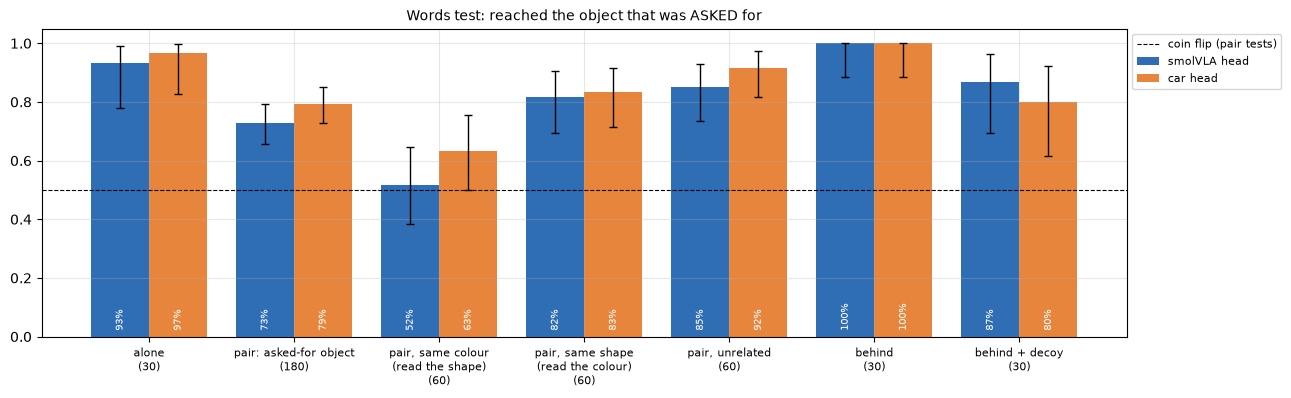

In [7]:
from carsim import evaluate as ev
MODELS = {NAMES[h]: TAGS[h] for h in CHECKPOINTS}
ev.words_chart(MODELS); plt.show()

**How to read it**
* **alone** and **behind**: basic driving and searching. Both heads should be near 100%. If not, something is wrong
  with the driving itself, not with reading.
* **pair: asked-for object** is the main reading score (180 drives, so its whiskers are narrow). Well above the dashed
  line means the model follows the words. The three bars after it split the pairs by what the decoy shares with the
  goal:
  * **same shape** (e.g. red ball vs blue ball): only the **colour** word tells them apart;
  * **same colour** (e.g. red ball vs red cube): only the **shape** word tells them apart. Expect this to be the
    lowest bar. From 2–3 m away and from the side, a cube and a cylinder of the same colour look very similar in a
    256×256 picture, and the original SmolVLM2 also finds this hardest;
  * **unrelated**: either word works.
* **behind + decoy**: the goal is behind the car and another object is right in front. The model must *not* drive to
  the visible object but turn and search. This is the hardest test of reading plus searching.

### 9.2 The standard test (ordinary rooms)

Same kind of bars, for 128 random rooms with obstacles. **goal hidden at start** is harder: the car must search, and
it has no memory, so once it turns away from something it has forgotten it. **touched something** is the share of
drives that touched an obstacle or wall at least once (lower is better; a touch doesn't end the drive).

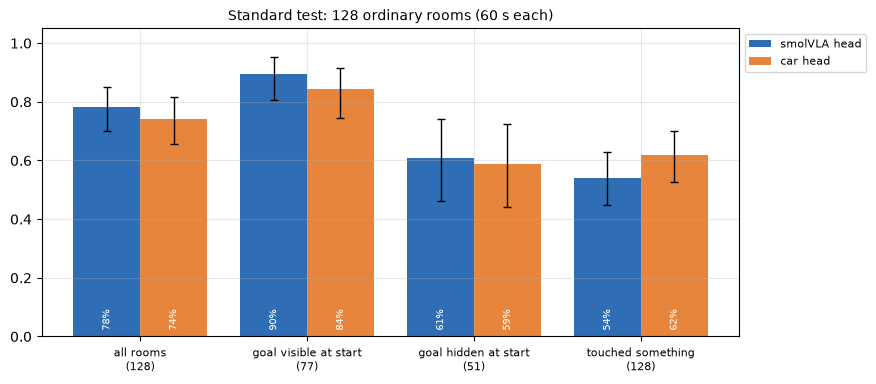

,alone,pair: asked-for object,behind + decoy,pair: went left (50% = no habit),standard: success,standard: touched something
smolVLA head,93%,73%,87%,49%,78%,54%
car head,97%,79%,80%,56%,74%,62%


In [8]:
ev.standard_chart(MODELS); plt.show()
ev.summary_table(MODELS).style.format("{:.0%}")

### 9.3 Is the difference between the heads real, or luck?

Both heads drove **exactly the same** test drives, so we compare them drive by drive. Drives that both got right, or
both got wrong, say nothing about which is better. What counts are the drives only one of them got right. If the two
heads were equally good, each of those drives would be a coin flip between them. `p` is the chance of a split at least
this uneven from luck alone. The usual rule of thumb: **p below 0.05 = very unlikely to be luck**.

In [9]:
for test in ("which", "standard"):
    print(ev.paired(TAGS["smolvla"], TAGS["car"], test, NAMES["smolvla"], NAMES["car"]))

pair drives (asked-for object): smolVLA head 73% vs car head 79% | only smolVLA head right: 21, only car head right: 33 | p = 0.134 (could easily be luck)
standard rooms: smolVLA head 78% vs car head 74% | only smolVLA head right: 14, only car head right: 9 | p = 0.405 (could easily be luck)


### 9.4 Look at the mistakes

Numbers say *how often*; pictures say *how*. Below: pair drives where the car head reached the **wrong** object, seen
from above. The asked-for object has a black outline; the dotted circle is the "reached" line. Look at what the two
objects have in common in each mistake (the title shows the instruction).

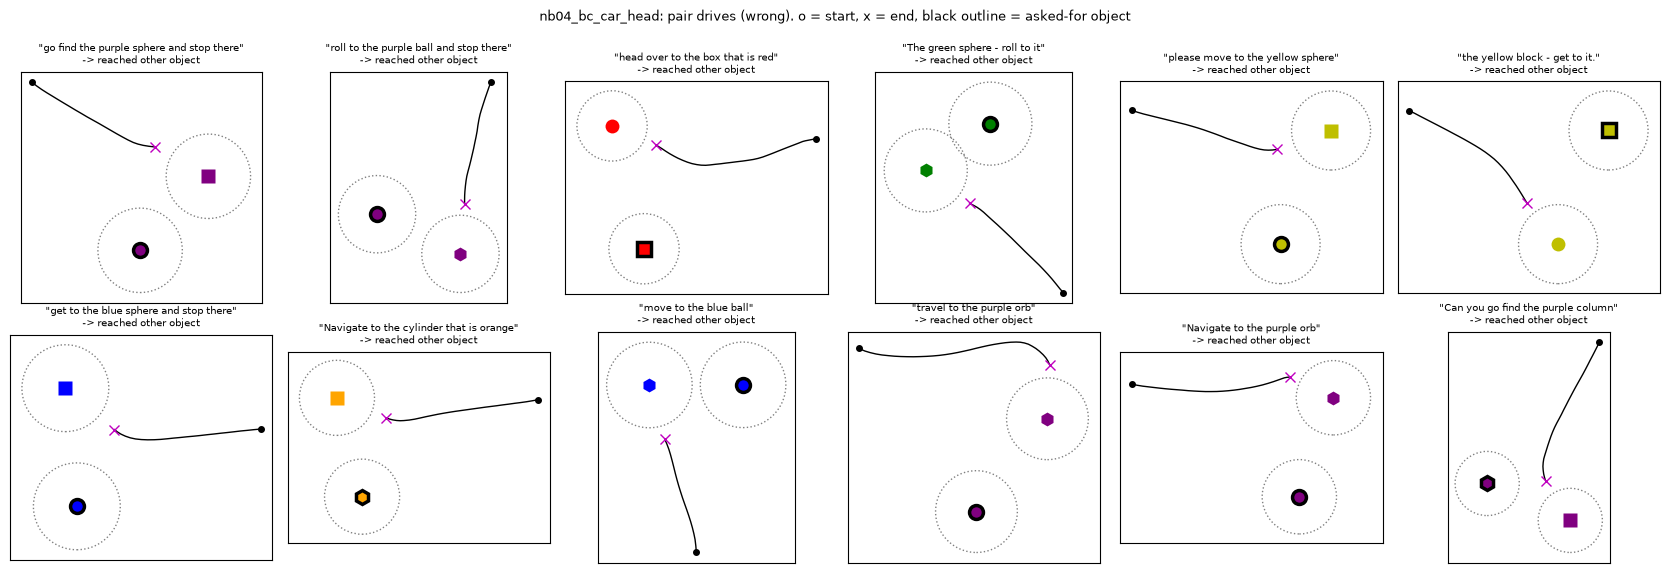

In [10]:
ev.plot_drives(TAGS["car"], "pair", only="wrong", n=12); plt.show()

### 9.5 Why do drives in ordinary rooms fail?

Every failed drive in the standard test is a 60 s timeout: the car never gives up, it just doesn't arrive. The table
breaks the test down (`carsim.evaluate.failure_table`):

* **success: goal visible / hidden at start**: how much harder searching is than driving to something in view;
* **drives that touched something**, **seconds touching per drive**: bumping into obstacles and walls;
* **stuck: 10 s or more touching**: failed drives where the car pressed against something for a long time;
* **goal out of view at the end**: failed drives that ended without the goal in the picture.

Then each failed drive is sorted into one group from its path (`failure_kinds`): **stuck on an obstacle** (10 s or
more touching), **parked at another object** (ended next to a non-goal object), **never saw the goal**, **saw it, then
lost it**, or **goal in view at the end**.

In [11]:
ev.failure_table(MODELS)

,smolVLA head,car head
success: all rooms,78%,74%
success: goal visible at start,90%,84%
success: goal hidden at start,61%,59%
drives that touched something,54%,62%
seconds touching per drive (mean),4.3,5.0
failed drives,28 of 128,33 of 128
... stuck: 10 s or more touching,10,16
... goal out of view at the end,27,28
"seconds to reach the goal (median, successes)",11.0,9.8


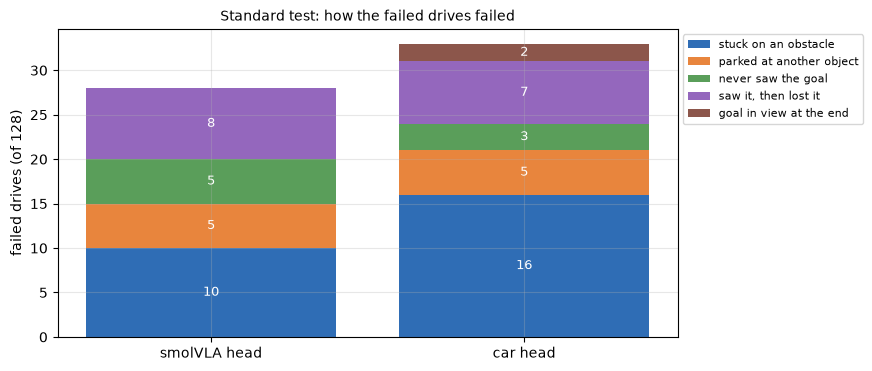

In [12]:
ev.failure_kinds_chart(MODELS); plt.show()

**Maps of failed drives** (car head). Blue = the path driven, red dots = where it was touching something, red dotted
= the shortest path, white star and dashed circle = the goal and its "reached" line, yellow wedge = what the camera saw
at the start. Look for: searching that turns away too early, circling in one area (no memory of where it has
looked), and getting pinned against an obstacle edge. These are the weaknesses notebook 05 lets the car practise.

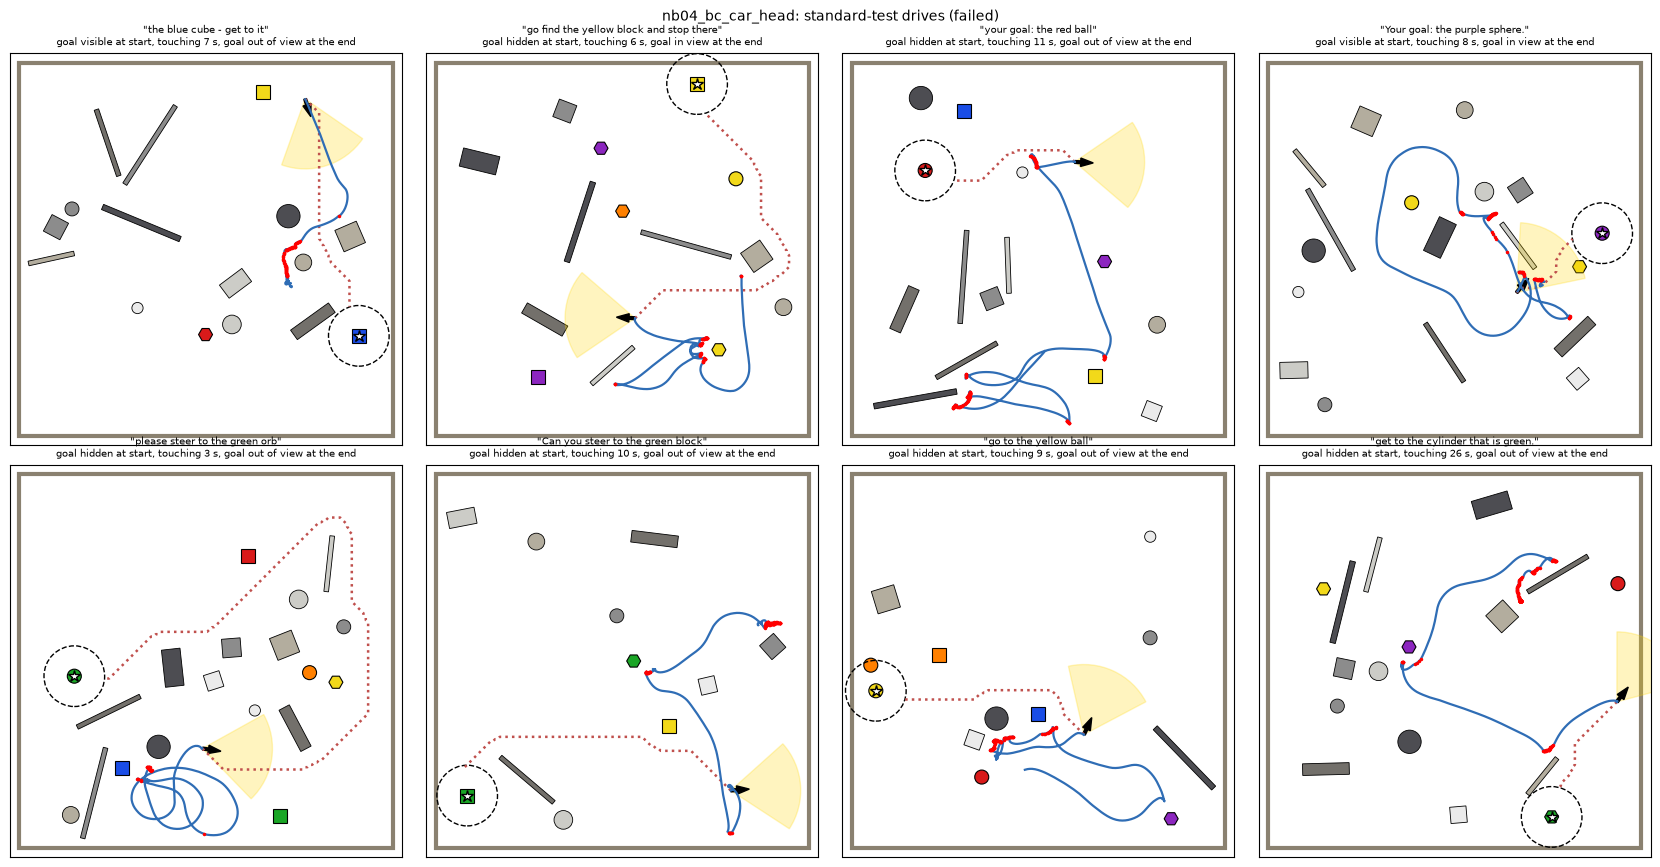

In [13]:
ev.plot_room_drives(TAGS["car"], only="failed", n=8); plt.show()

### 9.6 Watch it drive

The car-head model from section 7 drives one room in Genesis.

The video shows two views side by side. **Left:** the overhead camera (shown for you; this car never sees it). Blue = where the car has driven.
**Right:** the car's front camera, the only picture its own model sees. The text on top shows the time and whether the
car is touching something. The video plays at 2× speed.

**Settings:** `ROOM` = any layout seed (try others: every seed is a different room); `LIVE = True` also opens the
Genesis 3-D window with a chase camera and drives at real-time speed (needs a screen; the window closes when the drive
ends); `FORCE = True` drives again instead of reusing the saved video (in `runs/videos/`).

**One drive is an example, not a test.** The default room was picked to show the difference between the notebooks'
cars (it comes from the standard test, and the front-camera cars of notebooks 04 and 05 fail it). The success rates are
the tests above. A single drive can also differ from the same room in the test: the test words the instruction
differently (e.g. "move to" vs "head over to"), and small changes add up over a minute of driving.

**What you should see:** In the default room the goal is hidden behind a long wall at the start. This car finds it hard: it searches, bumps into obstacles and runs out of time (60 s). Notebook 05 lets it practise; notebook 06 gives it help from a ceiling camera.

In [ ]:
from carsim.viz import watch_drive
ROOM, LIVE, FORCE = 623600484, False, False
watch_drive(CHECKPOINTS["car"], room=ROOM, name="nb04_imitation_car", title="notebook 04: imitation", live=LIVE, force=FORCE)

{"room": 623600484, "prompt": "move to the blue cylinder", "success": false, "seconds": 60.0, "seconds_touching": 13.4, "video": "/home/mayur/Projects/obstacle_avoidance/runs/videos/nb04_imitation_car_room623600484.mp4"} (15 s to run)


### 9.7 What we found

The numbers below are from the project's own runs. Training is deterministic, so with the same random seed on the same
kind of GPU you get exactly these results (we checked: rerunning this notebook reproduced every weight and every test
drive). On other hardware expect small differences. To see how much is luck, we also trained everything with a second
random seed (`scripts/train_bc.py --head car --seed 1`):

| | smolVLA head, seed 0 / 1 | car head, seed 0 / 1 |
|---|---|---|
| pair: asked-for object | **73% / 82%** | **79% / 87%** |
| ... same colour (read the shape) | 52% / 67% | 63% / 70% |
| ... same shape (read the colour) | 82% / 83% | 83% / 93% |
| behind + decoy | 87% / 87% | 80% / 80% |
| alone / behind | 93–97% / 100% | 97% / 100% |
| standard: all rooms | **78% / 70%** | **74% / 74%** |
| standard: goal hidden at start | 61% / 59% | 59% / 65% |

**1. The model follows the words.** Every version picks the asked-for object of two far more often than a coin flip
(73–87%). For comparison, the same recipe with smolVLA's published input format (×31, two-way attention, no markers)
reached only 48–60% on this test and 48–62% in ordinary rooms: the reader input format of section 3 made the
biggest single difference in the whole project.

**2. The two heads are about equally good.** Drive by drive, neither head is better beyond luck (p = 0.13 for the words
test, 0.41 for the rooms; and the second seed agrees). The car head starts from random numbers, so smolVLA's
pretraining on robot arms gives no measurable advantage for this car once the reader is fed correctly. Note also how
much a second seed moves the scores (up to 9 points): one run alone can't rank two close models.

**3. What's still weak:**
* **Telling a cube from a cylinder of the same colour** (the "same colour" bars, 52–70%). From 2–3 m away and from the
  side the two shapes look alike in a 256×256 picture.
* **Searching and obstacles in ordinary rooms.** A hidden goal is found only about 60% of the time (78–90% when it is
  visible). Almost every failed drive ends with the goal out of view, and the biggest group of failures (10 of 28 for
  smolVLA's head, 16 of 33 for the car head) is getting **stuck against an obstacle** for 10 s or more. Two reasons:
  the car has **no memory** (it sees one picture at a time, so it can circle back to places it has already checked),
  and the scripted driver never touched anything, so the demonstrations never show how to back off after a bump.

Both of the last two are things a car can learn by practising, with a score that rewards finding the goal and
punishes touching things: that is notebook 05.

## 10. Summary and next step

**What we built**
- ✅ Imitation training (`carsim/bc_train.py`) of smolVLA on 296 scripted drives: reader in SmolVLM2's own input
  format, the last 4 reader layers unlocked, a random-object quiz, and live graphs.
- ✅ Two action heads with the same design: smolVLA's arm-pretrained head and a car head trained from scratch.
- ✅ Fixed driving tests with 95% ranges, a drive-by-drive comparison, and maps of the mistakes (`carsim/evaluate.py`).

**What you learned**
- A VLA = a vision-language *reader* + an *action head* that turns the reader's notes into actions by flow matching.
- A pretrained model only works if it is fed inputs the way it was trained: three small differences in the input
  format were enough to make the reader blind to which object the words meant.
- An auxiliary task (the quiz) can teach a skill the main task doesn't force, and the test must be designed so that
  the skill is the *only* way to pass (two objects, both instructions).
- Judge models by driving tests, with their luck ranges, not by training loss.

**Next: notebook 05, reinforcement learning.** The car practises in 8 simulators at once and learns from a score
instead of from demonstrations. Choose which of the two checkpoints to start from at the top of that notebook.